# PL19_EML

Merges two independently-developed reconstructors for the 19-port photonic
lantern's *spectral* (multi-wavelength) response:

1. **MLP** (cells under "MLP" below) -- straight from
   first 6 cells, unchanged: a single jaxMLP network trained on the full unrolled
   spectral feature vector (all native wavelengths x all fibres at once) to regress
   the aberration coefficients directly.
3. **Per-wavelength polynomial + multi-wavelength unwrap** (cells under
   "Polynomial" below) -- per-wavelength modelling
   section: one small degree-3-polynomial + OMP model per wavelength,
   trained on a *wrapped* (phasor) piston target, fused across wavelengths
   by a robust multi-wavelength unwrapper into the full-range estimate.
   `trainMLP_multiwavelength.ipynb`'s own polynomial/Zernike-ridge section
   is intentionally not included here.

Both sections load the same on-disk dataset (`DATASET_PATH`, built once by
the MLP section's data cell) and are otherwise independent of each other --
neither references the other's fitted model.

## MLP  

In [1]:
# =====================================================================
# CELL 0: ABSOLUTE TOP OF YOUR NOTEBOOK
# =====================================================================
import os

# FIX 1: Prevent Julia from overriding Python signal handles (Fixes the Segfault)
os.environ["PYTHON_JULIACALL_HANDLE_SIGNALS"] = "yes"

# FIX 2: Restrict Julia threads to keep it completely isolated from JAX/XLA thread pools
os.environ["JULIA_NUM_THREADS"] = "8"

# Force JAX backend configuration
os.environ["CBEAM_BACKEND"] = "jax"

import time
import warnings
import numpy as np
import jax
import jax.numpy as jnp

import cbeam
import matplotlib.pyplot as plt


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
# =====================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP
# =====================================================================
# Same reconstructors as trainMLP.ipynb (jaxMLP + PySR), but trained on the
# *spectral* response instead of a single wavelength: each sample's feature
# vector is the per-fiber power at every native wavelength in
# [MINW, MAXW], unrolled into one vector of length WVL_SAMPLES * N_SIGNALS
# (17 x 19 = 323 here) instead of just N_SIGNALS (19).
#
# We get that response straight from MultiWavelengthPropagationPipeline
# .get_power_spectra() -- see CELL 2. That's already the per-fiber power at
# each native wavelength (cbeam's ChainPropagator.to_channel_basis() does the
# modal -> per-core channel conversion internally), so there's no need for
# the detector-plane round trip multi_wavelength.ipynb does (simulate a
# dispersed image with SpectralImageSimulator, then recover per-fiber flux
# from it with SpectralExtractor) just to get back to numbers we already had
# right after propagation. That also means this notebook never needs the
# core-calibration / subpixel-sampling step trainMLP.ipynb uses at a single
# wavelength (calibrate_subpixel_centers / map_evaluated_to_ideal_geometry /
# LinearNDInterpolator) -- to_channel_basis already returns fiber-ordered
# output, so ideal_grid_positions isn't needed either.

import time

import jax
import jax.numpy as jnp
from jax import random

from jaxMLP import (
    init_mlp_params, mlp_forward, huber_loss, update_step, get_batches
)

from batch_propagation_pipeline import get_simulation_parameters, create_random_aberration_configs
from multi_wvl_pipeline import MultiWavelengthPropagationPipeline

# --- CONSTANTS ---
N_SIGNALS = 19      # lantern output cores (nrings=3)
M_MODES = 5          # aberration modes to reconstruct

# Native wavelength grid -- same interval used in multi_wavelength.ipynb.
WVL_SAMPLES = 41
MINW, MAXW = 700.0, 900.0   # nm

PISTON_SPAN = 5000

DATASET_PATH = f"10Klantern_training_data_multiwl_{WVL_SAMPLES}.npz"
#DATASET_PATH = "lantern_training_data_multiwl_hard.npz"


Using JAX backend.
Using diffrax for ODE integration.


In [3]:
# =====================================================================
# CELL 2: MULTI-WAVELENGTH DATA GENERATION, PROCESSING & I/O
# =====================================================================
LOAD_DATA_FROM_DISK = True  # Set to True to skip simulation and load saved arrays

if LOAD_DATA_FROM_DISK and os.path.exists(DATASET_PATH):
    print(f"Loading dataset from {DATASET_PATH}...")
    data = np.load(DATASET_PATH)

    X_train, X_val = data['X_train'], data['X_val']
    Y_train, Y_val = data['Y_train'], data['Y_val']
    X_mean, X_std = data['X_mean'], data['X_std']
    Y_mean, Y_std = data['Y_mean'], data['Y_std']
    native_wl_nm = data['native_wl_nm']

    print(f"Loaded successfully! Train samples: {X_train.shape[0]}, Val samples: {X_val.shape[0]}, "
          f"feature length: {X_train.shape[1]} ({len(native_wl_nm)} wavelengths x {N_SIGNALS} fibers)")

else:
    print("Generating new multi-wavelength pipeline dataset...")
    base_params = get_simulation_parameters(nrings=3)

    print("\n" + "="*60)
    print("SIMULATION PARAMETERS")
    print("="*60)
    print(f"Wavelength range: {MINW}-{MAXW} nm ({WVL_SAMPLES} native samples)")
    print(f"Lantern length: {base_params['z_ex']} μm")
    print(f"Cladding radius: {base_params['rclad']} μm")
    print(f"Taper factor: {base_params['taper_factor']}")
    print(f"Available influence function: {base_params['ifunc_file']}")

    # 1. Pipeline Execution
    import specula

    print("Initializing SPECULA GPU...")
    specula.init(0)
    from specula.data_objects.ifunc import IFunc

    print("Loading influence function...")
    print(base_params["ifunc_file"])
    ifunc = IFunc.restore(base_params["ifunc_file"])

    native_wl_nm = np.linspace(MINW, MAXW, WVL_SAMPLES)

    # auto_mode_bookkeeping=True: away from the 800 nm hard-coded degenerate-
    # group / skipped-mode config, degen_groups/skipped_modes are derived
    # per wavelength from a compute_neffs() probe instead (see
    # multi_wvl/bookkeeping.py) -- needed here since native_wl_nm spans
    # 760-840 nm, not just 800.
    mwp = MultiWavelengthPropagationPipeline(
        base_params=base_params,
        ifunc=ifunc,
        native_wavelengths_nm=native_wl_nm,
        field_gen_on_gpu=False,
        field_gen_chunk_size=64,
        auto_mode_bookkeeping=True,
    )

    N_SAMPLES = 50000
    # coeff, _labels = create_sparse_aberration_configs_mono(n=N_SAMPLES, m=M_MODES, minv=-300, maxv=300)
    coeff, _labels = create_random_aberration_configs(n=N_SAMPLES, m=M_MODES, minv=-PISTON_SPAN, maxv=PISTON_SPAN)

    # power_spectra: (n_wavelengths, N_SAMPLES, n_fibers) real per-fiber flux,
    # already scaled by each field's input coupling efficiency so it stays
    # comparable across fields and across wavelengths (see
    # MultiWavelengthPropagationPipeline.get_power_spectra's docstring).
    # output_wavelengths_nm is left at its default (None): that returns
    # power at the native solve grid directly (wl_out == native_wl_nm) with
    # no interpolation, instead of interpolating onto a grid that's the same
    # as the native one anyway.
    power_spectra, wl_out = mwp.get_power_spectra(
        coeff,
        use_gpu=False,
        prop_chunk_size=32,
    )
    print(f"\npower_spectra shape: {power_spectra.shape}  "
          f"(n_wavelengths={power_spectra.shape[0]}, n_fields={power_spectra.shape[1]}, "
          f"n_fibers={power_spectra.shape[2]})")

    # 2. Unroll the wavelength axis into the feature vector.
    # power_spectra is (n_wl, n_fields, n_fibers); move fields to the front and
    # flatten (n_wl, n_fibers) -> one vector per field, wavelength-major (each
    # wavelength's N_SIGNALS fiber powers are contiguous). Order doesn't matter
    # to the MLP, only that it's applied consistently -- it is, since this is
    # the only place X_raw is built.
    X_raw = jnp.asarray(
        np.asarray(power_spectra).transpose(1, 0, 2).reshape(power_spectra.shape[1], -1)
    )
    Y_raw = jnp.array(coeff)

    print(f"Unrolled feature vector length: {X_raw.shape[1]} "
          f"({len(native_wl_nm)} wavelengths x {N_SIGNALS} fibers)")

    # 3. Scaling and Splitting
    X_mean, X_std = jnp.mean(X_raw, axis=0), jnp.std(X_raw, axis=0) + 1e-6
    Y_mean, Y_std = jnp.mean(Y_raw, axis=0), jnp.std(Y_raw, axis=0) + 1e-6
    X_scaled, Y_scaled = (X_raw - X_mean) / X_std, (Y_raw - Y_mean) / Y_std

    split_idx = int(0.8 * N_SAMPLES)
    X_train, X_val = X_scaled[:split_idx], X_scaled[split_idx:]
    Y_train, Y_val = Y_scaled[:split_idx], Y_scaled[split_idx:]

    # 4. Save Data for Next Time
    print(f"Saving dataset to {DATASET_PATH}...")
    np.savez(DATASET_PATH, X_train=X_train, Y_train=Y_train, X_val=X_val, Y_val=Y_val,
             X_mean=X_mean, X_std=X_std, Y_mean=Y_mean, Y_std=Y_std,
             native_wl_nm=native_wl_nm)
    print("Dataset generated and saved!")


Loading dataset from 10Klantern_training_data_multiwl_41.npz...
Loaded successfully! Train samples: 40000, Val samples: 10000, feature length: 779 (41 wavelengths x 19 fibers)


In [4]:
# =====================================================================
# CELL 3: MLP TRAINING EXECUTION
# =====================================================================
main_key = random.PRNGKey(42)
init_key, train_key = random.split(main_key, 2)

INPUT_DIM = X_train.shape[1]   # WVL_SAMPLES * N_SIGNALS (323 at the defaults above)

# Input grew ~17x (N_SIGNALS -> WVL_SAMPLES * N_SIGNALS), but the added
# information did not: adjacent native wavelengths see nearly the same
# aberration through a smoothly-varying dispersive response, so the extra
# columns are highly correlated, not independent. Widen the hidden layers
# (64 -> 128) rather than scale them by 17x.
layer_sizes = [INPUT_DIM, 256, 256, 256, 256, M_MODES]
params = init_mlp_params(layer_sizes, init_key)


In [5]:
EPOCHS = 40000
BATCH_SIZE = 128
LEARNING_RATE = 1e-2

# =====================================================================
# Fit-or-load.  Training is by far the most expensive step in this
# notebook, so the weights are written to disk when it finishes and
# reloaded on later runs instead of retraining.
#
# The tag is DERIVED from everything that would invalidate the weights --
# architecture, optimiser settings, training-set shape -- rather than
# hand-typed, for the reason spelled out in CELL 0: a hand-typed tag goes
# stale silently when a parameter changes, and you reload a model trained
# on something else with no error to tell you.
#
# Set RETRAIN = True to force a fresh fit even when a cached one exists.
# =====================================================================
import os, pickle

RETRAIN  = False
MLP_DIR  = "model_cache_multiwl"
MLP_TAG  = (f"mlp-{'x'.join(map(str, layer_sizes))}"
            f"-e{EPOCHS}-b{BATCH_SIZE}-lr{LEARNING_RATE:g}"
            f"-n{X_train.shape[0]}x{X_train.shape[1]}-m{M_MODES}")
MLP_PATH = os.path.join(MLP_DIR, MLP_TAG + ".pkl")


def save_mlp(path, params, train_losses, val_losses):
    """Store the weights as plain numpy: a pickle of jax device arrays is tied
    to the jax version and to the device it was created on."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    blob = {
        "weights":      [np.asarray(w) for w in params["weights"]],
        "biases":       [np.asarray(b) for b in params["biases"]],
        "train_losses": np.asarray(train_losses, float),
        "val_losses":   np.asarray(val_losses, float),
        "layer_sizes":  list(layer_sizes),
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LEARNING_RATE,
    }
    tmp = path + ".tmp"                 # write-then-rename: an interrupted save
    with open(tmp, "wb") as f:          # must not leave a half-written model
        pickle.dump(blob, f)            # that later loads as if it were fine
    os.replace(tmp, path)


def load_mlp(path):
    with open(path, "rb") as f:
        blob = pickle.load(f)
    if blob["layer_sizes"] != list(layer_sizes):
        raise ValueError(f"cached model is {blob['layer_sizes']}, this notebook "
                         f"wants {list(layer_sizes)} -- delete {path} or set RETRAIN")
    params = {"weights": [jnp.asarray(w) for w in blob["weights"]],
              "biases":  [jnp.asarray(b) for b in blob["biases"]]}
    return params, list(blob["train_losses"]), list(blob["val_losses"])


if not RETRAIN and os.path.exists(MLP_PATH):
    params, train_losses, val_losses = load_mlp(MLP_PATH)
    # recompute the validation loss rather than trusting the stored curve, so a
    # mismatched dataset shows up here instead of in the plots downstream
    _vl = float(huber_loss(Y_val, mlp_forward(params, X_val, deterministic=True)))
    print(f"[mlp] loaded {MLP_PATH}")
    print(f"      {len(train_losses)} epochs | stored val loss "
          f"{val_losses[-1]:.6f} | recomputed {_vl:.6f}")
else:
    print(f"\n--- Starting Wavefront Inversion Loop ({EPOCHS} Epochs) ---")
    train_losses, val_losses = [], []

    for epoch in range(1, EPOCHS + 1):
        start_epoch = time.time()
        train_key, batch_key = random.split(train_key)
        batches = get_batches(X_train, Y_train, BATCH_SIZE, batch_key)

        epoch_loss = 0.0
        for X_batch, Y_batch in batches:
            train_key, step_key = random.split(train_key)
            params, loss_val = update_step(params, X_batch, Y_batch, step_key, LEARNING_RATE)
            epoch_loss += loss_val
        epoch_loss /= len(batches)

        Y_val_pred = mlp_forward(params, X_val, deterministic=True)
        val_loss = huber_loss(Y_val, Y_val_pred)

        train_losses.append(epoch_loss)
        val_losses.append(val_loss)

        if epoch % 50 == 0 or epoch == 1:
            print(f"Epoch {epoch:03d} | Train Loss: {epoch_loss:.6f} | Val Loss: {val_loss:.6f} "
                  f"| {time.time() - start_epoch:.3f} s/epoch")

    save_mlp(MLP_PATH, params, train_losses, val_losses)
    print(f"[mlp] saved {MLP_PATH}")

[mlp] loaded model_cache_multiwl/mlp-779x256x256x256x256x5-e40000-b128-lr0.01-n40000x779-m5.pkl
      40000 epochs | stored val loss 0.000428 | recomputed 0.000428


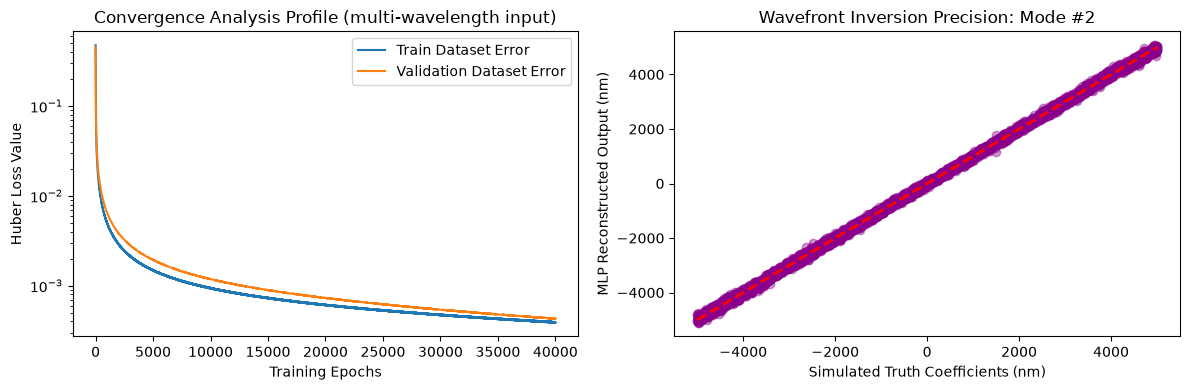

In [6]:
# =====================================================================
# CELL 5: DIAGNOSTIC PERFORMANCE ANALYSIS
# =====================================================================
Y_val_pred_scaled = mlp_forward(params, X_val, deterministic=True)
Y_val_pred_physical = (Y_val_pred_scaled * Y_std) + Y_mean
Y_val_true_physical = (Y_val * Y_std) + Y_mean

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Dataset Error')
plt.plot(val_losses, label='Validation Dataset Error')
plt.yscale('log')
plt.xlabel('Training Epochs')
plt.ylabel('Huber Loss Value')
plt.title('Convergence Analysis Profile (multi-wavelength input)')
plt.legend()

plt.subplot(1, 2, 2)
target_mode = 2
plt.scatter(Y_val_true_physical[:, target_mode], Y_val_pred_physical[:, target_mode], alpha=0.4, color='darkmagenta')
plt.plot([Y_val_true_physical.min(), Y_val_true_physical.max()], [Y_val_true_physical.min(), Y_val_true_physical.max()], 'r--', lw=2)
plt.xlabel('Simulated Truth Coefficients (nm)')
plt.ylabel('MLP Reconstructed Output (nm)')
plt.title(f'Wavefront Inversion Precision: Mode #{target_mode}')
plt.tight_layout()
plt.show()


## Per-wavelength polynomial fitting + multi-wavelength unwrap  

In [7]:
# --- fibre subset ---------------------------------------------------
# Which of the N_SIGNALS output-fibre signals each per-lambda model sees.
#   FIB_KEEP   : explicit list of fibre indices, e.g. [0,1,2,3,4,5,6] (wins if not None)
#   FIB_STRIDE : otherwise keep every FIB_STRIDE-th fibre  (1 -> all N_SIGNALS)
FIB_KEEP   = None
FIB_STRIDE = 1

FIB_USE = (np.asarray(FIB_KEEP, int) if FIB_KEEP is not None
           else np.arange(0, N_SIGNALS, FIB_STRIDE))
assert FIB_USE.ndim == 1 and len(FIB_USE) >= 2, FIB_USE
assert FIB_USE.min() >= 0 and FIB_USE.max() < N_SIGNALS, FIB_USE

print(f"fibres         : {N_SIGNALS} per wl  ->  using {len(FIB_USE)}:  idx {list(map(int, FIB_USE))}")


fibres         : 19 per wl  ->  using 19:  idx [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]


In [8]:
# =====================================================================
# CELL A : PER-WAVELENGTH SETUP   (phase-wrapped piston reconstruction)
# ---------------------------------------------------------------------
# Idea: instead of ONE model over all 17 wavelengths, fit ONE model per
# wavelength.  At wavelength lam the fibre signals only see piston
# MODULO lam -- the interference pattern repeats every lam of piston
# (single pass: phase = 2*pi*piston/lam).  So each per-wavelength model
# is trained to recover the WRAPPED piston  wrap(p, lam)  in
# [-lam/2, lam/2).  After the 17 models each give their in-range
# estimate, a multi-wavelength UNWRAPPER (CELL E) fuses them into the
# full +-PISTON_SPAN estimate.
#
# Features : the 19 raw fibre powers at that one wavelength.  No Zernike
#            projection, no cross-wavelength features.
# Model    : degree-3 polynomial + OMP, K = 1280   (CELL B / CELL D).
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

W_ALL = int(WVL_SAMPLES)
LAM   = np.asarray(native_wl_nm, float)          # (17,) native wavelengths [nm]
PSPAN = float(PISTON_SPAN)                        # piston truth lies in [-PSPAN, PSPAN] nm
Mp    = int(M_MODES)                              # number of independent pistons

WRAP_FACTOR = 0.5        # 1.0 = single pass (period = lam) ; 0.5 = double pass (lam/2)
PERIODS     = LAM * WRAP_FACTOR                   # wrap period per wavelength [nm]

# --- wavelength subset --------------------------------------------------
# Which native wavelengths get a per-lambda model (and are fused in CELL D).
#   WL_KEEP   : explicit list of indices, e.g. [0, 4, 8, 12, 16]  (wins if not None)
#   WL_STRIDE : otherwise keep every WL_STRIDE-th wavelength   (1 -> all W_ALL)
WL_KEEP   = None
WL_STRIDE = 2

WL_USE = (np.asarray(WL_KEEP, int) if WL_KEEP is not None
          else np.arange(0, W_ALL, WL_STRIDE))
assert WL_USE.ndim == 1 and len(WL_USE) >= 2, WL_USE
assert WL_USE.min() >= 0 and WL_USE.max() < W_ALL, WL_USE

DATA_SHARE = 0.2                                 # fraction of train rows to use per per-wl fit (1.0 = all)
FIT_SEED   = 0                                   # RNG seed for the DATA_SHARE row subsample

def wrap(x, T):
    """map x into [-T/2, T/2)  (mod T).  T scalar or broadcastable."""
    return x - T * np.round(x / T)


# spectral feature vector  ->  (n, wavelength, fibre)   (CELL 2 is wavelength-major)
Xtr3 = np.asarray(X_train, float).reshape(-1, W_ALL, N_SIGNALS)
Xva3 = np.asarray(X_val,   float).reshape(-1, W_ALL, N_SIGNALS)

# physical piston targets  (undo the CELL 2 standardisation)
Yp_tr = np.asarray(Y_train) * np.asarray(Y_std) + np.asarray(Y_mean)   # (n, Mp) nm
Yp_va = np.asarray(Y_val)   * np.asarray(Y_std) + np.asarray(Y_mean)

print(f"pistons        : {Mp} independent, range +-{PSPAN:.0f} nm  (std {Yp_tr.std():.0f} nm)")
print(f"wavelengths    : {W_ALL} native  ->  using {len(WL_USE)}:  "
      f"idx {list(map(int, WL_USE))}  = {LAM[WL_USE].round(1)} nm")
print(f"wrap period    : factor {WRAP_FACTOR}  ->  {PERIODS.min():.1f} .. {PERIODS.max():.1f} nm")
print(f"                 a single wl alone resolves only "
      f"+-{PERIODS.min()/2:.0f} .. +-{PERIODS.max()/2:.0f} nm  (<< {PSPAN:.0f})")
print(f"data           : train {Xtr3.shape[0]}, val {Xva3.shape[0]}, {N_SIGNALS} fibres/wl")


pistons        : 5 independent, range +-5000 nm  (std 2887 nm)
wavelengths    : 41 native  ->  using 21:  idx [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]  = [700. 710. 720. 730. 740. 750. 760. 770. 780. 790. 800. 810. 820. 830.
 840. 850. 860. 870. 880. 890. 900.] nm
wrap period    : factor 0.5  ->  350.0 .. 450.0 nm
                 a single wl alone resolves only +-175 .. +-225 nm  (<< 5000)
data           : train 40000, val 10000, 19 fibres/wl


In [9]:
# =====================================================================
# CELL B : HELPERS  --  degree-d OMP polynomial models + phasor targets
# ---------------------------------------------------------------------
# fit_omp_poly / predict_omp_poly are the same degree-d OMP used in
# -Copy1 (poly features -> per-target Orthogonal Matching Pursuit with a
# hard term budget K), applied two ways below:
#   - fit_perwavelength_omp : one small model per wavelength (19 fibre
#     inputs each), regressing the WRAPPED piston -- OMP version 1 (CELL C).
#   - fit_global_omp        : one model over ALL of WL_USE's wavelengths
#     at once, regressing the piston directly -- OMP version 2 (CELL F).
# Both take their data/config as explicit parameters rather than reading
# module globals, so they can be called more than once (different degree,
# different wavelength selection, ...) without stepping on each other or
# on whatever CELL A/C/F have set at top level.
# =====================================================================
import os
import pickle
import time
import warnings

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import OrthogonalMatchingPursuit, Ridge

warnings.filterwarnings("ignore", message="Orthogonal matching pursuit ended prematurely")

DEG    = 3
K      = 1000
SCREEN = 2000              # >= #deg-3 monomials of 19 inputs -> no real screening
CACHE_DIR = "model_cache_perlambda"

RETRAIN = False    # True -> refit every cached() model below even if a cache file exists


def cached(name, build):
    os.makedirs(CACHE_DIR, exist_ok=True)
    path = os.path.join(CACHE_DIR, name.replace("/", "__").replace(" ", "_") + ".pkl")
    if not RETRAIN and os.path.exists(path):
        try:
            with open(path, "rb") as f:
                return pickle.load(f)
        except Exception as e:                                   # noqa: BLE001
            print(f"  [cache] load failed {name} ({e}); refit")
    obj = build()
    try:
        with open(path, "wb") as f:
            pickle.dump(obj, f)
        print(f"  [cache] fit  {name}")
    except Exception as e:                                       # noqa: BLE001
        print(f"  [cache] not saved {name} ({e})")
    return obj


def _rows(n_have, share, seed):
    """share in (0, 1]: a uniformly-random subset of n_have row indices (sorted,
    no replacement); share >= 1 (or the rounded count >= n_have) just uses all of them."""
    n_want = max(1, int(round(share * n_have)))
    if n_want >= n_have:
        return np.arange(n_have)
    return np.sort(np.random.default_rng(seed).choice(n_have, size=n_want, replace=False))


def omp_fit(Ztr, y, K, screen):
    yc  = y - y.mean()
    sel = np.argsort(-np.abs(Ztr.T @ yc))[:min(screen, Ztr.shape[1])]
    omp = OrthogonalMatchingPursuit(
        n_nonzero_coefs=min(K, len(sel) - 1)).fit(Ztr[:, sel], y)
    return omp, sel


def fit_omp_poly(F_tr, Ycols_tr, deg=DEG, K=K, screen=SCREEN):
    """degree-`deg` polynomial features + per-column OMP (term budget K).
    F_tr (n, d) inputs ; Ycols_tr (n, t) targets  ->  (pf, sc, [(omp, sel)] * t).

    StandardScaler(copy=False): transform in place instead of allocating a
    second full-size array. For the per-wavelength models (CELL C, 19-ish
    raw inputs) this is unmeasurable; for fit_global_omp's combined-
    wavelength inputs (CELL F, hundreds of raw inputs -> a dense polynomial
    expansion with a huge column count) the default copy=True doubles peak
    memory on both the fit and predict side (predict_omp_poly reuses this
    same fitted `sc`, so the fix applies there too) -- confirmed by an
    actual out-of-memory crash on the copy=True default at CELL F's scale.
    """
    pf  = PolynomialFeatures(deg, include_bias=False)
    Ztr = pf.fit_transform(F_tr)
    sc  = StandardScaler(copy=False).fit(Ztr)
    Ztr = sc.transform(Ztr)
    fits = [omp_fit(Ztr, Ycols_tr[:, j], K, screen) for j in range(Ycols_tr.shape[1])]
    return pf, sc, fits


def predict_omp_poly(model, F):
    pf, sc, fits = model
    Z = sc.transform(pf.transform(F))
    return np.stack([o.predict(Z[:, s]) for (o, s) in fits], axis=1)


# ---- phasor target representation ----------------------------------
# A model can't regress the sawtooth wrap(p, T) directly -- it has a
# branch cut in the middle of its output range.  Regress the smooth
# phasor instead:  [sin(2*pi p/T), cos(2*pi p/T)]  (2*Mp columns), then
# decode  ghat = atan2(sin, cos) * T/2pi  in [-T/2, T/2)  plus a
# per-sample confidence  r = hypot(sin, cos)  (~1 = the model is sure).
def phasor_targets(Yp, T):
    ph = 2 * np.pi * Yp / T
    return np.concatenate([np.sin(ph), np.cos(ph)], axis=1)          # (n, 2*Mp)


def phasor_decode(P, T):
    M = P.shape[1] // 2
    s, c = P[:, :M], P[:, M:]
    return np.arctan2(s, c) * T / (2 * np.pi), np.hypot(s, c)


# ---- shared feature builders -----------------------------------------
def build_feature_matrix(X3, wl_use, fib_use):
    """(n, len(wl_use)*len(fib_use)) flattened features for the given
    wavelength/fibre subset, wavelength-major (matches CELL 2's own layout).
    Used by fit_global_omp() and the linear baseline in CELL E."""
    return X3[:, wl_use][:, :, fib_use].reshape(len(X3), -1)


def perwavelength_features(X3, w, fib_use, nb_wl=0):
    """(n, d) features for a per-lambda model at wavelength index w: fibres
    fib_use, wavelengths w-nb_wl .. w+nb_wl (clipped to X3's own wavelength
    axis). Used by fit_perwavelength_omp()."""
    w_all = X3.shape[1]
    lo, hi = max(0, w - nb_wl), min(w_all, w + nb_wl + 1)
    return X3[:, lo:hi][:, :, fib_use].reshape(len(X3), -1)


# ---- OMP version 1: one model per wavelength, wrapped-phasor target ---
def fit_perwavelength_omp(Xtr3, Xva3, Yp_tr, Yp_va, periods, wl_use, fib_use,
                          deg, k, screen, nb_wl=0, data_share=1.0, fit_seed=0,
                          tag=""):
    """Fit one degree-`deg` OMP model per wavelength in wl_use, each on a
    data_share-sampled subset of training rows, regressing the WRAPPED
    (phasor) piston at that wavelength's own period (periods[w]).

    Returns a dict ready for report_unwrap():
        {"GHAT_va", "CONF_va", "SIG_tr", "SIG_va", "lam_use", "wl_use", "elapsed"}
    """
    wl_use  = np.asarray(wl_use, int)
    lam_use = periods[wl_use]
    nva     = Xva3.shape[0]
    Mp      = Yp_tr.shape[1]
    rows    = _rows(Xtr3.shape[0], data_share, fit_seed)

    GHAT_va = np.zeros((nva, Mp, len(wl_use)))
    CONF_va = np.zeros_like(GHAT_va)
    SIG_tr  = np.zeros((len(wl_use), Mp))
    SIG_va  = np.zeros((len(wl_use), Mp))

    ds_tag    = "" if data_share >= 1.0 else f"-ds{data_share:g}"
    cache_tag = f"d{deg}-K{k}-nb{nb_wl}-f{len(fib_use)}{ds_tag}{tag}"

    t0 = time.time()
    for i, w in enumerate(wl_use):
        T = periods[w]
        model = cached(
            f"perlambda-{cache_tag}-w{w}",
            lambda w=w, T=T: fit_omp_poly(
                perwavelength_features(Xtr3, w, fib_use, nb_wl)[rows],
                phasor_targets(Yp_tr[rows], T), deg=deg, K=k, screen=screen))
        g_va, r_va = phasor_decode(
            predict_omp_poly(model, perwavelength_features(Xva3, w, fib_use, nb_wl)), T)
        g_tr, _ = phasor_decode(
            predict_omp_poly(model, perwavelength_features(Xtr3, w, fib_use, nb_wl)[rows]), T)

        GHAT_va[:, :, i], CONF_va[:, :, i] = g_va, r_va
        SIG_va[i] = np.sqrt(np.mean(wrap(g_va - wrap(Yp_va, T), T) ** 2, axis=0))
        SIG_tr[i] = np.sqrt(np.mean(wrap(g_tr - wrap(Yp_tr[rows], T), T) ** 2, axis=0))

    return dict(GHAT_va=GHAT_va, CONF_va=CONF_va, SIG_tr=SIG_tr, SIG_va=SIG_va,
                lam_use=lam_use, wl_use=wl_use, elapsed=time.time() - t0)


# ---- OMP version 2: one model over ALL wavelengths, direct target -----
def fit_global_omp(Xtr3, Xva3, Yp_tr, Yp_va, wl_use, fib_use, deg, k, screen,
                    data_share=1.0, fit_seed=0, tag=""):
    """One OMP model per piston mode, fit on the FULL flattened feature
    vector across every wavelength in wl_use at once -- as opposed to
    fit_perwavelength_omp's one-model-per-wavelength split. Regresses the
    raw (unwrapped) piston directly: no phasor targets, no wrap/unwrap step,
    since a model that sees every wavelength's constraint jointly can (in
    principle) resolve the fringe ambiguity on its own.

    Returns (rmse, Y_pred_va) -- rmse shape (Mp,) nm, Y_pred_va shape (n_val, Mp).
    """
    rows  = _rows(Xtr3.shape[0], data_share, fit_seed)
    Xb_tr = build_feature_matrix(Xtr3, wl_use, fib_use)[rows]
    Xb_va = build_feature_matrix(Xva3, wl_use, fib_use)

    ds_tag     = "" if data_share >= 1.0 else f"-ds{data_share:g}"
    cache_name = f"global-omp-d{deg}-K{k}-w{len(wl_use)}-f{len(fib_use)}{ds_tag}{tag}"

    model = cached(cache_name,
                   lambda: fit_omp_poly(Xb_tr, Yp_tr[rows], deg=deg, K=k, screen=screen))
    pred  = predict_omp_poly(model, Xb_va)
    rmse  = np.sqrt(np.mean((pred - Yp_va) ** 2, axis=0))
    return rmse, pred


print(f"helpers ready | deg {DEG}, K {K} | cache -> {CACHE_DIR}/  | RETRAIN={RETRAIN}")


helpers ready | deg 3, K 1000 | cache -> model_cache_perlambda/  | RETRAIN=False



fitted 21 per-wavelength models (deg 3) in 42.5s

per-wavelength WRAPPED-piston RMSE (nm)  [val]
   wl(nm) |  +-T/2 |   p0   p1   p2   p3   p4
    700.0 |    175 |     8     8     7     8     7
    710.0 |    178 |     9     7     6     7     9
    720.0 |    180 |     9     7     6     7     9
    730.0 |    182 |     8    11     9    11     8
    740.0 |    185 |     9    10     4    10    10
    750.0 |    188 |     6     8     6     8     6
    760.0 |    190 |    10     9     7     9    10
    770.0 |    192 |     9     8     6     8    10
    780.0 |    195 |     9     8     1     8     9
    790.0 |    198 |     7    11     4    11     7
    800.0 |    200 |    11     9     7     9    11
    810.0 |    202 |    11     9     5     8    11
    820.0 |    205 |     6    10     4    10     6
    830.0 |    208 |    10    10     5    10    10
    840.0 |    210 |    10     8     8     8    10
    850.0 |    212 |    10    10     7     8    11
    860.0 |    215 |     9    10     7  

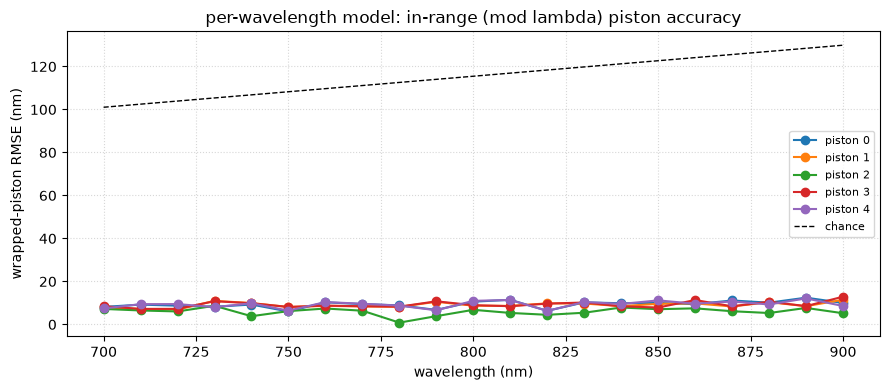

In [10]:
# =====================================================================
# CELL C : OMP version 1 (current) -- fit ONE degree-DEG OMP model per
#   wavelength via fit_perwavelength_omp() (CELL B).  Each model -> wrapped
#   piston estimate  ghat_w in [-T_w/2, T_w/2)  + a per-sample confidence.
#   Cached one file per wavelength.  Fused into the full-range estimate by
#   CELL D right below.
# =====================================================================
NB_WL = 0     # wavelength half-window per model: 0 = wl w only, 1 = w-1..w+1, ...

v1 = fit_perwavelength_omp(Xtr3, Xva3, Yp_tr, Yp_va, PERIODS, WL_USE, FIB_USE,
                           deg=DEG, k=K, screen=SCREEN, nb_wl=NB_WL,
                           data_share=DATA_SHARE, fit_seed=FIT_SEED)
GHAT_va, CONF_va = v1["GHAT_va"], v1["CONF_va"]
SIG_tr, SIG_va   = v1["SIG_tr"], v1["SIG_va"]
lam_use, wl_use  = v1["lam_use"], v1["wl_use"]

print(f"\nfitted {len(wl_use)} per-wavelength models (deg {DEG}) in {v1['elapsed']:.1f}s\n")

# ---- per-wavelength "competence": how well each model recovers the
#      in-range (wrapped) piston.  chance ~ (period)/sqrt(12).
print("per-wavelength WRAPPED-piston RMSE (nm)  [val]")
print("   wl(nm) |  +-T/2 | " + " ".join(f"  p{k}" for k in range(Mp)))
for i, w in enumerate(wl_use):
    print(f"  {LAM[w]:7.1f} | {lam_use[i]/2:6.0f} | " +
          " ".join(f"{SIG_va[i, k]:5.0f}" for k in range(Mp)))
print(f"  {'mean':>7s} | {'':6s} | " + " ".join(f"{SIG_va[:, k].mean():5.0f}" for k in range(Mp)) +
      f"     (chance ~ {lam_use.mean() / np.sqrt(12):.0f})")

fig, ax = plt.subplots(figsize=(9, 4))
for k in range(Mp):
    ax.plot(LAM[wl_use], SIG_va[:, k], "o-", label=f"piston {k}")
ax.plot(LAM[wl_use], lam_use / np.sqrt(12), "k--", lw=1, label="chance")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("wrapped-piston RMSE (nm)")
ax.set_title("per-wavelength model: in-range (mod lambda) piston accuracy")
ax.legend(fontsize=8)
ax.grid(True, ls=":", alpha=.5)
plt.tight_layout()
plt.show()


FINAL full-range piston reconstruction:
  piston |  RMSE(nm) |  bias  | wrong-fringe | RMSE(q>=0.6) kept% | no-unwrap ref
     0   |      1.9  |     +0 |       0.0%  |      1.9  100%   |      2901
     1   |      1.9  |     +0 |       0.0%  |      1.9  100%   |      2882
     2   |      0.7  |     +0 |       0.0%  |      0.7  100%   |      2877
     3   |      1.9  |     +0 |       0.0%  |      1.9  100%   |      2899
     4   |      1.9  |     -0 |       0.0%  |      1.9  100%   |      2862
  mean RMSE 1.6 | wrong-fringe 0.0% | kept RMSE 1.6 on 100% of samples


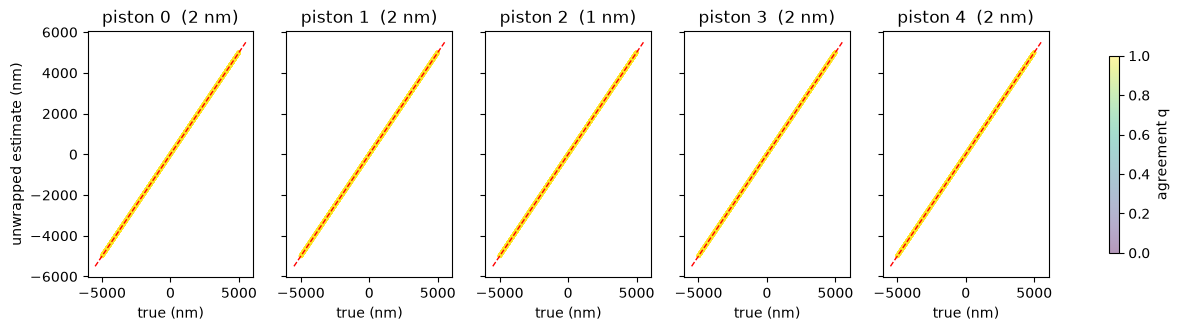

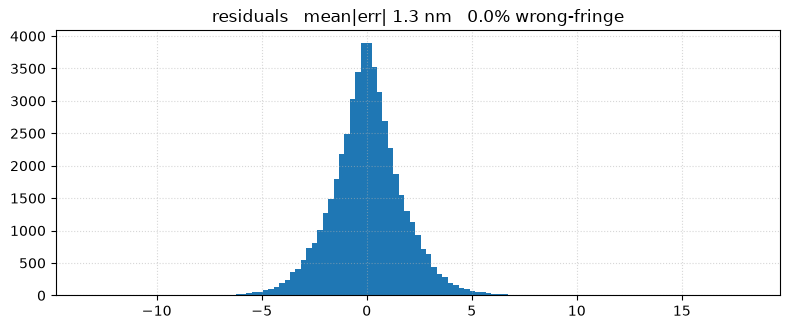

In [11]:
# =====================================================================
# CELL D : multi-wavelength UNWRAP  (robust) -- fuses OMP v1's per-
#   wavelength wrapped estimates into the full +-PISTON_SPAN estimate.
#   J(p) = -sum_w  W_{s,w} * cos(phi_{s,w} - 2*pi*p/lam_w)     [von Mises / circular ML]
#   W_{s,w} = conf_{s,w} * (lam_w / (2*pi*sig_w))^2  , with confidence gating
#   coarse grid (whole range) -> fine grid (+-2.5 mean periods) -> IRLS/Huber polish
#
#   unwrap() and report_unwrap() take every quantity they need as a
#   parameter (ghat/conf/lam/sig/pspan/Mp/... ) instead of reading CELL A's
#   globals directly, so report_unwrap() can be reused for any per-
#   wavelength-model output shaped like OMP v1's, not just this one call.
# =====================================================================
CONF_MIN = 0.15     # ignore a wl for a sample if hypot(sin,cos) < this ("don't know")
HUBER_C  = 2.0      # Huber cutoff in robust-sigma units (fringe-jump rejection)
N_IRLS   = 12
QGATE    = 0.6      # report an extra RMSE over samples with agreement q >= QGATE


def unwrap(ghat, conf, lam, sig, pspan, conf_min=CONF_MIN, huber_c=HUBER_C,
          n_irls=N_IRLS, chunk=4000):
    S, Wn = ghat.shape
    phi   = 2 * np.pi * ghat / lam[None, :]                          # (S, Wn) in [-pi, pi)
    kappa = (lam / (2 * np.pi * np.maximum(sig, 1e-6))) ** 2         # (Wn,) phase concentration
    base  = np.where(conf >= conf_min, conf, 0.0) * kappa[None, :]   # (S, Wn)
    base  = np.where(base.sum(1, keepdims=True) > 0, base, kappa[None, :])  # all-gated -> ungate
    wn    = (2 * np.pi / lam)[None, :, None]                         # (1, Wn, 1)
    mp    = float(lam.mean())

    def vm_cost(cand):                                               # cand (c, G) -> (c, G)
        return -np.einsum("cw,cwg->cg", base_c,
                          np.cos(phi_c[:, :, None] - wn * cand[:, None, :]))

    # ---- stage 1: coarse grid over the whole range ----
    step  = max(lam.min() / 4, 2 * pspan / 6000)
    g1    = np.arange(-pspan, pspan + step, step)
    p0    = np.empty(S)
    for a in range(0, S, chunk):
        phi_c, base_c = phi[a:a + chunk], base[a:a + chunk]
        p0[a:a + chunk] = g1[vm_cost(np.broadcast_to(g1, (len(phi_c), g1.size))).argmin(1)]

    # ---- stage 2: fine grid, +-2.5 mean periods around p0 ----
    win, sf = 2.5 * mp, max(lam.min() / 30, mp / 400)
    rel     = np.arange(-win, win + sf, sf)
    p1      = np.empty(S)
    for a in range(0, S, chunk):
        phi_c, base_c = phi[a:a + chunk], base[a:a + chunk]
        cand = np.clip(p0[a:a + chunk, None] + rel[None, :], -pspan, pspan)
        p1[a:a + chunk] = cand[np.arange(len(cand)), vm_cost(cand).argmin(1)]

    # ---- stage 3: IRLS / Huber weighted mean with integer fringe fixing ----
    p = p1
    for _ in range(n_irls):
        c  = ghat + np.round((p[:, None] - ghat) / lam[None, :]) * lam[None, :]
        r  = c - p[:, None]
        s  = 1.4826 * np.median(np.abs(r), axis=1, keepdims=True) + 1e-9
        wt = base * np.minimum(1.0, huber_c * s / np.maximum(np.abs(r), 1e-9))
        den = wt.sum(1)
        p_new = np.where(den > 0, (wt * c).sum(1) / np.maximum(den, 1e-12), p)
        if np.max(np.abs(p_new - p)) < 1e-6:
            p = p_new; break
        p = p_new

    # ---- stage 4: per-sample agreement score ----
    c     = ghat + np.round((p[:, None] - ghat) / lam[None, :]) * lam[None, :]
    used  = base > 0
    q     = (np.abs(c - p[:, None]) < lam[None, :] / 4) & used
    q     = q.sum(1) / np.maximum(used.sum(1), 1)
    return np.clip(p, -1.5 * pspan, 1.5 * pspan), q


def report_unwrap(GHAT_va, CONF_va, lam_use, SIG_tr, SIG_va, Yp_va, pspan, Mp,
                  qgate=QGATE, label="", make_plots=True, **unwrap_kwargs):
    """Fuse per-wavelength wrapped estimates (unwrap(), one call per piston
    mode) into the full-range estimate, print the summary table, and
    (optionally) the two diagnostic plots -- exactly what this cell used to
    do inline for OMP v1 only; now reusable for any per-wavelength-model
    output shaped the same way.

    Returns (rmse, Phat_va, QUAL_va) -- rmse shape (Mp,) nm.
    """
    out     = [unwrap(GHAT_va[:, k, :], CONF_va[:, k, :], lam_use, SIG_tr[:, k], pspan,
                      **unwrap_kwargs)
               for k in range(Mp)]
    Phat_va = np.stack([o[0] for o in out], axis=1)
    QUAL_va = np.stack([o[1] for o in out], axis=1)

    rmse  = np.sqrt(np.mean((Phat_va - Yp_va) ** 2, axis=0))
    gross = np.mean(np.abs(Phat_va - Yp_va) > lam_use.min() / 2, axis=0)
    bias  = np.mean(Phat_va - Yp_va, axis=0)
    best_w   = SIG_va.mean(1).argmin()
    ref_rmse = np.sqrt(np.mean((GHAT_va[:, :, best_w] - Yp_va) ** 2, axis=0))

    keep     = QUAL_va >= qgate
    rmse_ok  = np.array([np.sqrt(np.mean((Phat_va[keep[:, k], k] - Yp_va[keep[:, k], k]) ** 2))
                         if keep[:, k].any() else np.nan for k in range(Mp)])

    print(f"FINAL full-range piston reconstruction{f' ({label})' if label else ''}:")
    print(f"  piston |  RMSE(nm) |  bias  | wrong-fringe | RMSE(q>={qgate}) kept% | no-unwrap ref")
    for k in range(Mp):
        print(f"    {k:2d}   | {rmse[k]:8.1f}  | {bias[k]:+6.0f} | {100*gross[k]:9.1f}%  | "
              f"{rmse_ok[k]:8.1f} {100*keep[:,k].mean():4.0f}%   | {ref_rmse[k]:9.0f}")
    print(f"  mean RMSE {rmse.mean():.1f} | wrong-fringe {100*gross.mean():.1f}% | "
          f"kept RMSE {np.nanmean(rmse_ok):.1f} on {100*keep.mean():.0f}% of samples")

    if make_plots:
        fig, ax = plt.subplots(1, Mp, figsize=(3.1 * Mp, 3.2), sharex=True, sharey=True)
        ax = np.atleast_1d(ax)
        for k in range(Mp):
            sc = ax[k].scatter(Yp_va[:, k], Phat_va[:, k], c=QUAL_va[:, k], s=4, alpha=.4,
                               cmap="viridis", vmin=0, vmax=1)
            lim = 1.1 * pspan
            ax[k].plot([-lim, lim], [-lim, lim], "r--", lw=1)
            ax[k].set_title(f"piston {k}  ({rmse[k]:.0f} nm)"); ax[k].set_xlabel("true (nm)")
        ax[0].set_ylabel("unwrapped estimate (nm)")
        fig.colorbar(sc, ax=ax, label="agreement q", shrink=.8)
        plt.show()

        fig, ax = plt.subplots(figsize=(8, 3.4))
        err = (Phat_va - Yp_va).ravel(); lo = lam_use.min()
        ax.hist(np.clip(err, -lo, lo), bins=121)
        ax.set_title(f"residuals   mean|err| {np.mean(np.abs(err)):.1f} nm   "
                     f"{100*np.mean(np.abs(err) > lo/2):.1f}% wrong-fringe")
        ax.grid(True, ls=":", alpha=.5); plt.tight_layout(); plt.show()

    return rmse, Phat_va, QUAL_va


rmse, Phat_va, QUAL_va = report_unwrap(GHAT_va, CONF_va, lam_use, SIG_tr, SIG_va, Yp_va, PSPAN, Mp)


In [ ]:
# =====================================================================
# CELL F : OMP version 2 -- ONE degree-DEG2 OMP model per piston mode,
#   fit on the FULL flattened feature vector across every wavelength in
#   WL_USE at once (fit_global_omp(), CELL B) -- no per-wavelength split,
#   no wrap/unwrap: a model that sees every wavelength jointly can, in
#   principle, resolve the fringe ambiguity on its own.
#
#   Degree 3 (same degree as OMP v1/CELL C) over ALL of WL_USE's 21
#   wavelengths x all 19 fibres (399 inputs) is infeasible as a single
#   combined model: ~10.7M degree-3 polynomial terms, hundreds of GiB just
#   for the feature matrix -- confirmed by an actual OOM crash when tried.
#   To keep WL_USE exactly as CELL C uses it (same wavelength selection,
#   per the request this replaces the old degree-2/399-input version) while
#   still fitting degree 3:
#     - FIB_USE2 halves the fibres (~10 of 19) -> 210 inputs, ~1.59M terms.
#       Still too big to be materialised TWICE, which is what
#       fit_omp_poly/predict_omp_poly's StandardScaler used to do by
#       default -- confirmed by a second OOM at this exact configuration.
#     - StandardScaler(copy=False) (CELL B) removes that redundant copy, so
#       only one (10000, ~1.59M) float64 matrix (~120 GiB) is ever held at
#       once instead of two. DATA_SHARE2 doesn't change this peak -- the
#       fixed-size 10000-row validation matrix dominates regardless of how
#       many rows are used for training.
# =====================================================================
WL_STRIDE = 4

WL_USE = (np.asarray(WL_KEEP, int) if WL_KEEP is not None
          else np.arange(0, W_ALL, WL_STRIDE))

DEG2        = 3
FIB_USE2    = FIB_USE[::1]      # ~10 of 19 fibres (half); WL_USE itself is unchanged from CELL C
DATA_SHARE2 = DATA_SHARE        # same row share as OMP v1 (doesn't affect peak memory here --
                                 # see the note above)
SCREEN = 6000

t0 = time.time()
rmse_v2, Yhat_v2 = fit_global_omp(Xtr3, Xva3, Yp_tr, Yp_va, WL_USE, FIB_USE2,
                                  deg=DEG2, k=K, screen=SCREEN,
                                  data_share=DATA_SHARE2, fit_seed=FIT_SEED)
elapsed_v2 = time.time() - t0

n_inputs = len(WL_USE) * len(FIB_USE2)
print(f"fitted global degree-{DEG2} OMP model ({len(WL_USE)} wl x {len(FIB_USE2)} "
      f"fibres = {n_inputs} inputs, {DATA_SHARE2:.0%} of train rows) in {elapsed_v2:.1f}s")
print(f"full-range piston RMSE (nm), degree-{DEG2} OMP over all {len(WL_USE)} wavelengths at once:")
for k in range(Mp):
    print(f"    {k:2d}   | {rmse_v2[k]:8.1f}")
print(f"  mean   | {rmse_v2.mean():8.1f}")


In [ ]:
# =====================================================================
# CELL E : final comparison -- MLP, OMP v1 (per-wavelength deg-DEG +
#          unwrap), OMP v2 (deg-DEG2, all wavelengths at once), and a
#          linear (Ridge) reference over the same WL_USE spectral vector.
#
#   Linear (Ridge) reference: with piston range +-PSPAN >> lambda the raw
#   spectral -> piston map is many-to-one, so a single LINEAR model cannot
#   resolve the fringe ambiguity -- this is exactly what OMP v1's
#   per-wavelength + unwrap split (and OMP v2's nonlinearity, via the
#   degree-DEG2 polynomial features) are built to fix. It is printed below
#   for reference but deliberately left out of the final plot, which only
#   compares the three models that actually attempt the reconstruction.
#
#   MLP reference: Y_val_pred_physical, already computed once in the MLP
#   section's own diagnostic cell (CELL 5) from the full unrolled spectral
#   vector (all WVL_SAMPLES wavelengths, not just WL_USE) -- reused here,
#   not recomputed.
# =====================================================================
RUN_BASELINE = True

if RUN_BASELINE:
    Xb_tr = build_feature_matrix(Xtr3, WL_USE, FIB_USE)
    Xb_va = build_feature_matrix(Xva3, WL_USE, FIB_USE)
    lin = cached(f"baseline-linear-w{len(WL_USE)}-f{len(FIB_USE)}",
                 lambda: Ridge(1.0).fit(Xb_tr, Yp_tr))

    rb   = np.sqrt(np.mean((lin.predict(Xb_va) - Yp_va) ** 2, axis=0))
    rmlp = np.sqrt(np.mean((np.asarray(Y_val_pred_physical) - Yp_va) ** 2, axis=0))

    print(f"full-range piston RMSE (nm):   [{len(WL_USE)} wl]")
    print(f"  piston | linear(all wl) |    MLP    | per-wl deg-{DEG} OMP + unwrap | deg-{DEG2} OMP (all wl)")
    for k in range(Mp):
        print(f"    {k:2d}   | {rb[k]:13.1f}  | {rmlp[k]:8.1f}  | {rmse[k]:23.1f}   | {rmse_v2[k]:15.1f}")
    print(f"  mean   | {rb.mean():13.1f}  | {rmlp.mean():8.1f}  | {rmse.mean():23.1f}   | {rmse_v2.mean():15.1f}")

    # linear/Ridge is print-only above (an unskilled reference point) -- the
    # plot compares only the three models that actually reconstruct piston.
    x = np.arange(Mp)
    wbar = 0.25
    plt.figure(figsize=(9, 4))
    plt.bar(x - wbar, rmlp,    wbar, label="MLP (full spectral vector)")
    plt.bar(x,        rmse,    wbar, label=f"per-wl deg-{DEG} OMP + unwrap")
    plt.bar(x + wbar, rmse_v2, wbar, label=f"deg-{DEG2} OMP (all wl)")
    plt.axhline(Yp_tr.std(), color="k", ls=":", lw=1, label="prior std (no skill)")
    plt.xticks(x, [f"piston {k}" for k in range(Mp)])
    plt.ylabel("full-range RMSE (nm)")
    plt.title("multi-wavelength piston reconstruction")
    plt.legend(fontsize=8)
    plt.grid(True, axis="y", ls=":", alpha=.5)
    plt.tight_layout()
    plt.show()
else:
    print("RUN_BASELINE = False")
